## Preprocessing Training Citra Rontgen Osteoarthritis menggunakan CLAHE, Gaussian, Edge Detection, Morphological, Grayscale

#### Import Library untuk Preprocessing

In [5]:
import cv2
import os
import matplotlib.pyplot as plt

#### Mendefinisikan Path Input dan Output

In [8]:
# Folder input
input_folder = r'C:\Users\Asus\PENELITIAN_RINI_VAMULIA_OA_CNN\DataSetOA_6200\TrainOA_4960'

# Folder output untuk setiap tahap preprocessing
output_base = r'C:\Users\Asus\PENELITIAN_RINI_VAMULIA_OA_CNN\Processed_TrainOA'
output_folders = {
    "CLAHE": os.path.join(output_base, "CLAHE"),
}

#### Membuat Folder Output Otomatis

In [11]:
def create_folders():
    for folder in output_folders.values():
        os.makedirs(folder, exist_ok=True)
        for grade in range(5):
            grade_folder = os.path.join(folder, f"Grade{grade}")
            os.makedirs(grade_folder, exist_ok=True)

#### Mendefinisikan Fungsi-fungsi Preprocessing

In [14]:
# Fungsi untuk menampilkan gambar per tahap
def display_images(images, titles, grade, img_count):
    plt.figure(figsize=(15, 5))
    plt.suptitle(f"Grade {grade} - Image {img_count + 1}")
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(image, cmap='gray')
        plt.title(title)
        plt.axis('off')
    plt.show()

# Fungsi CLAHE preprocessing
def preprocess_clahe(image):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(image)

#### Mendefinisikan Fungsi Utama Preprocessing

In [22]:
# Fungsi utama untuk menjalankan semua tahap preprocessing
def process_images():
    create_folders()

    for grade_folder in os.listdir(input_folder):
        grade_path = os.path.join(input_folder, grade_folder)
        if os.path.isdir(grade_path):
            print(f"Processing Grade: {grade_folder}")

            count = 0
            for filename in os.listdir(grade_path):
                if filename.endswith(('.jpg', '.png')):
                    img_path = os.path.join(grade_path, filename)
                    image = cv2.imread(img_path, 0)

                    # CLAHE
                    clahe_image = preprocess_clahe(image)
                    clahe_output_path = os.path.join(output_folders["CLAHE"], grade_folder, f"clahe_{filename}")
                    cv2.imwrite(clahe_output_path, clahe_image)

                    # Tampilkan gambar 2 per grade
                    if count < 2:
                        display_images(
                            [image, clahe_image],
                            ["Original", "CLAHE"],
                            grade_folder, count
                        )
                        count += 1

            print(f"Processing for {grade_folder} completed!\n")

#### Menjalankan Preprocessing

Processing Grade: .ipynb_checkpoints
Processing for .ipynb_checkpoints completed!

Processing Grade: Grade0


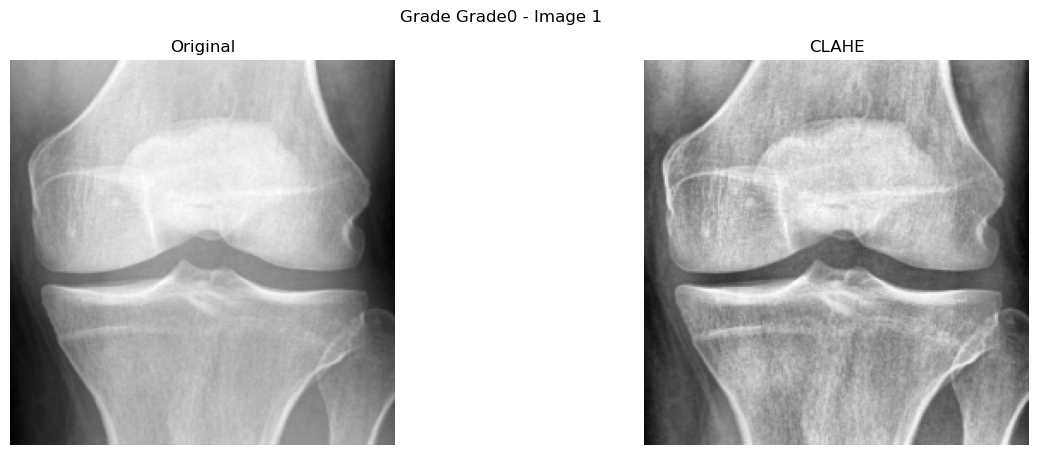

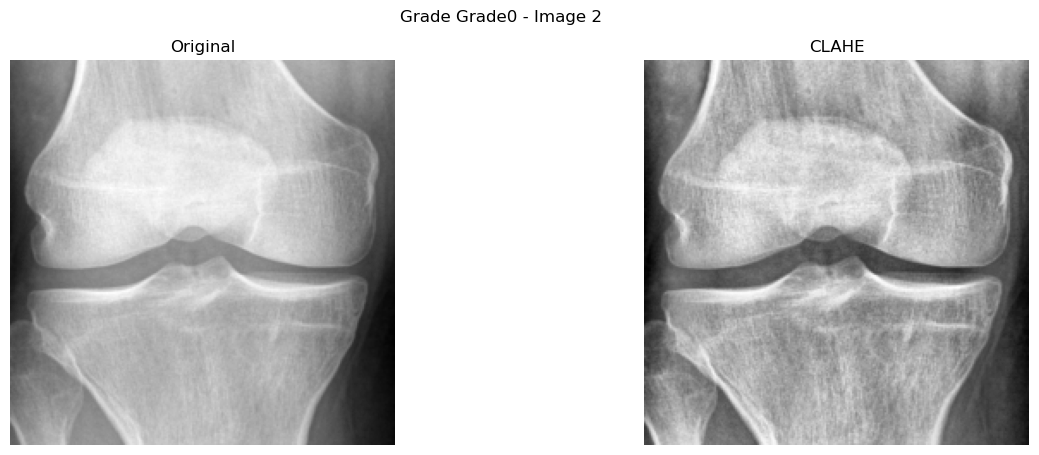

Processing for Grade0 completed!

Processing Grade: Grade1


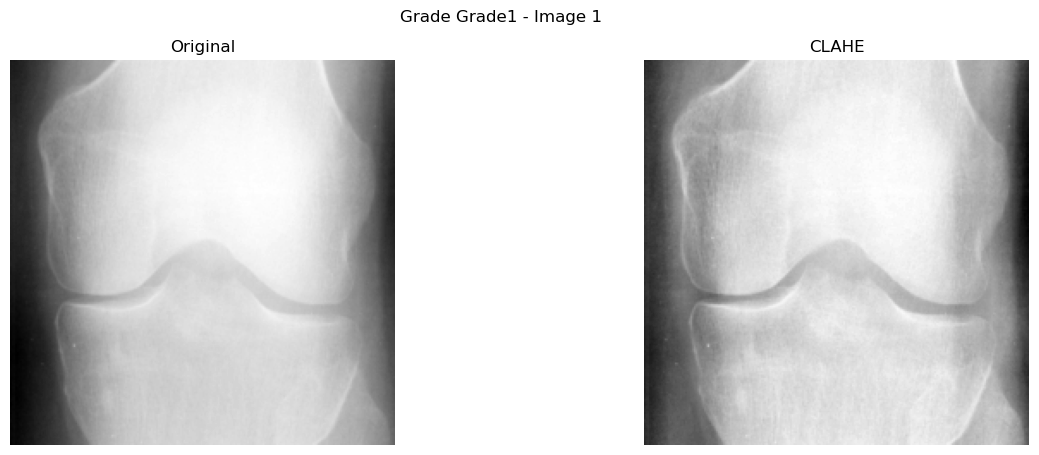

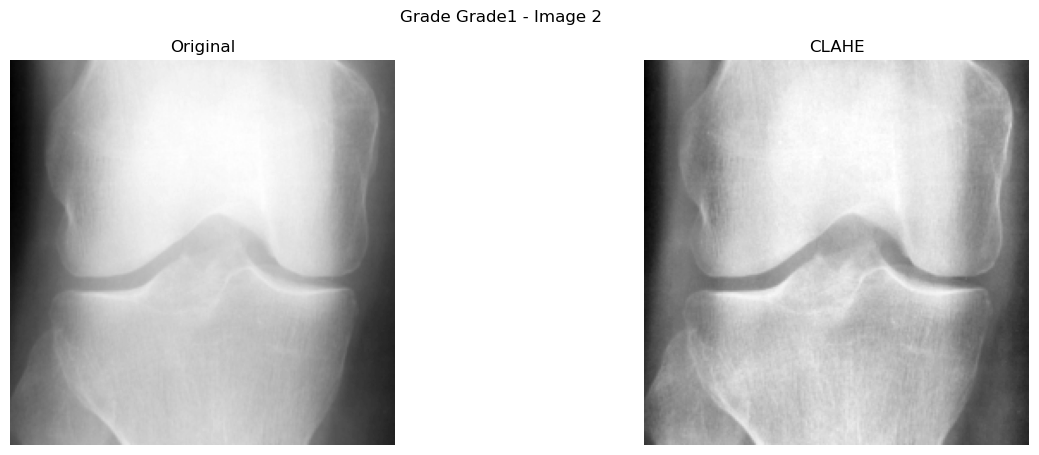

Processing for Grade1 completed!

Processing Grade: Grade2


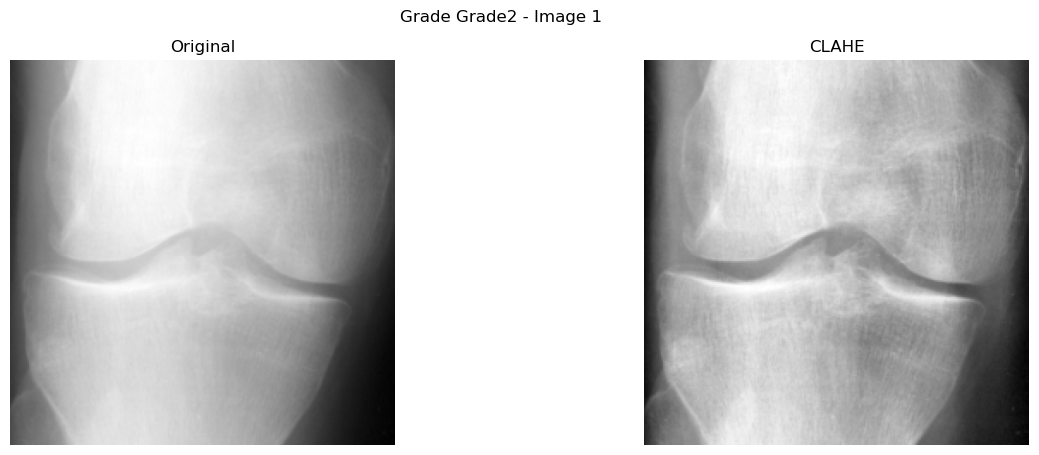

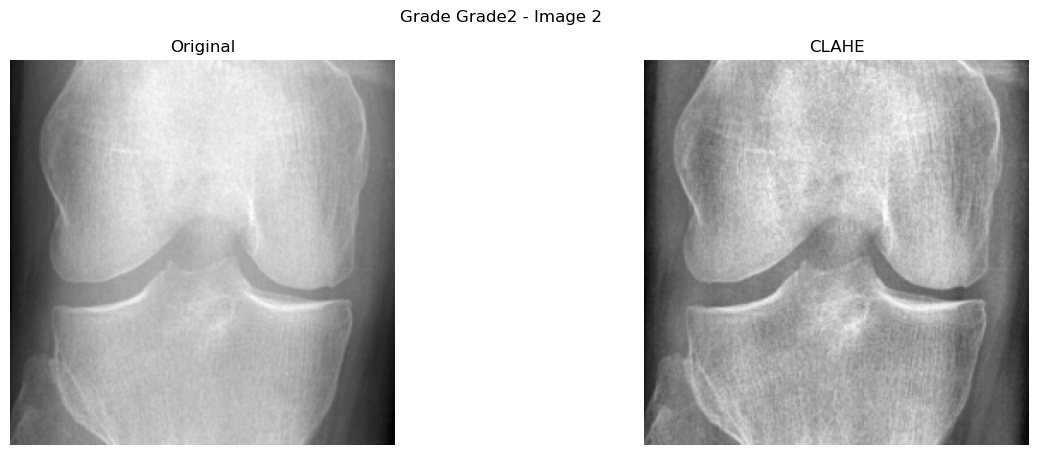

Processing for Grade2 completed!

Processing Grade: Grade3


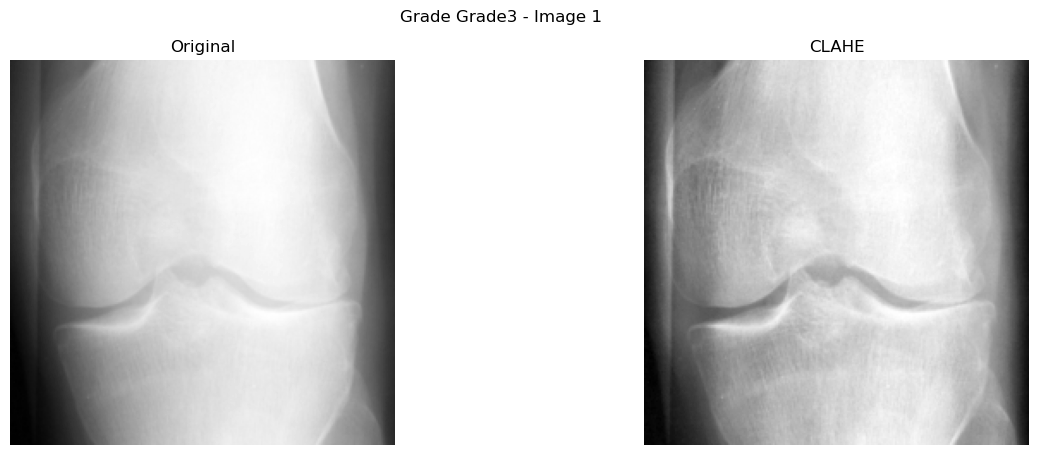

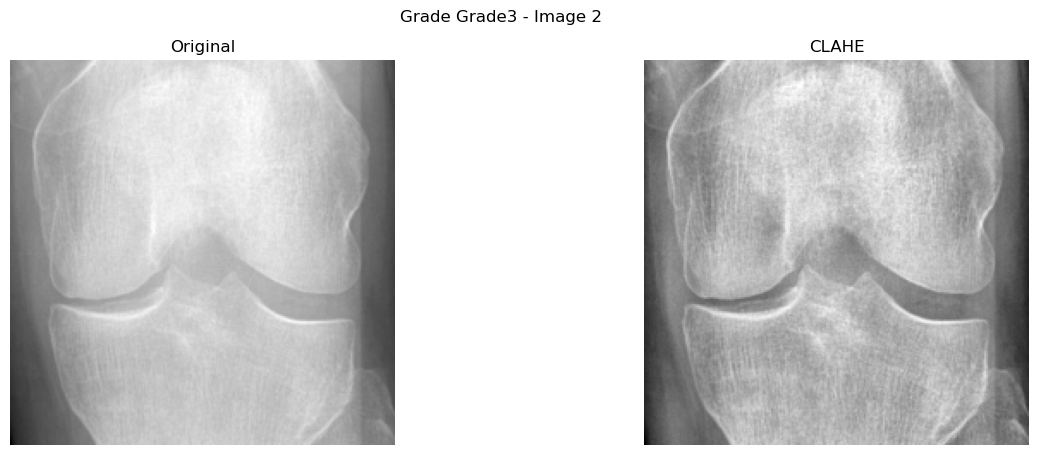

Processing for Grade3 completed!

Processing Grade: Grade4


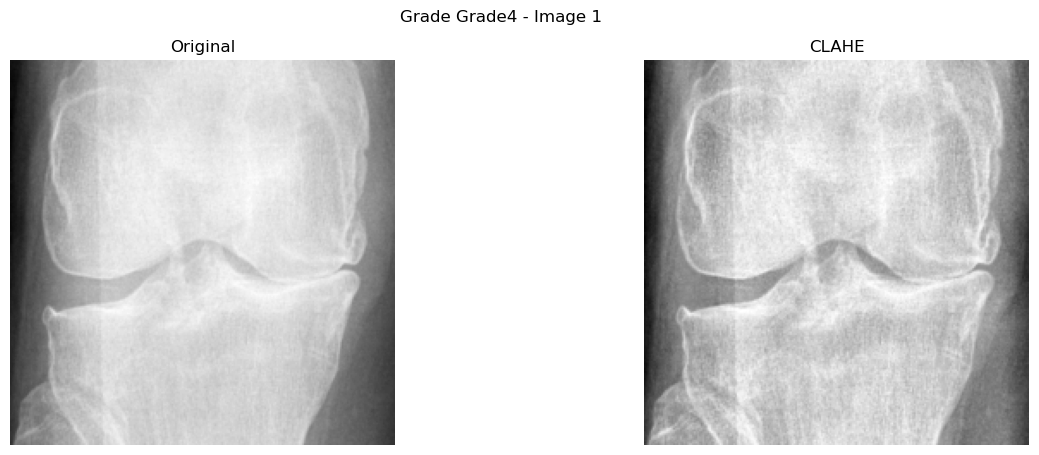

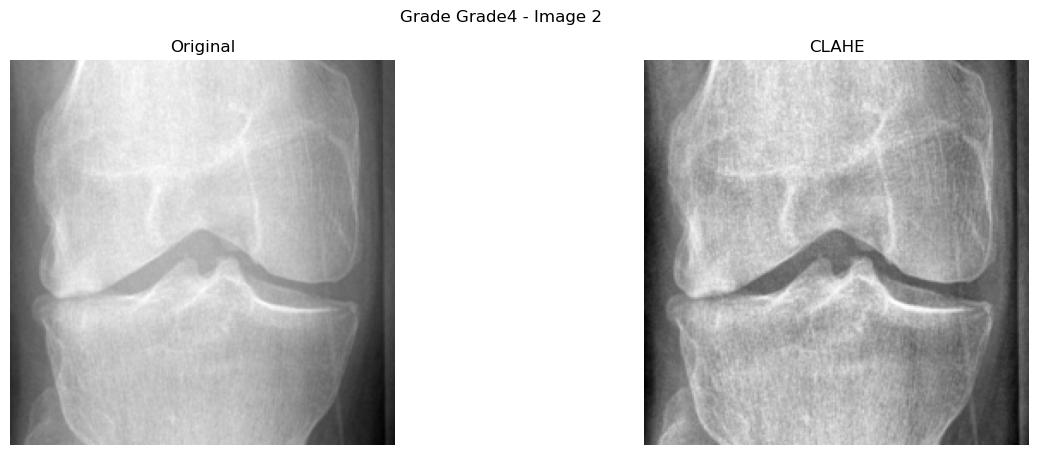

Processing for Grade4 completed!

Preprocessing complete for all grades!


In [25]:
process_images()
print("Preprocessing complete for all grades!")